# L3 - Pretty plotting: matplotlib

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import random

## Q7: Mandelbrot set

The [Mandelbrot set](https://en.wikipedia.org/wiki/Mandelbrot_set) is defined such that $z_{k+1} = z_k^2 + c$
remains bounded, which is usually taken as $|z_{k+1}| <= 2$
where $c$ is a complex number and we start with $z_0 = 0$

We want to consider a range of $c$, as complex numbers $c = x + iy$,
where $-2 < x < 2$ and $-2 < y < 2$.

For each $c$, identify its position on a Cartesian grid as $(x,y)$ and 
assign a value $N$ that is the number of iterations, $k$, required for $|z_{k+1}|$ to become greater than $2$.

The plot of this function is called the Mandelbrot set.

Here's a simple implementation that just does a fixed number of iterations and then colors points in Z depending on whether they satisfy $|z| \le 2$.  

Your task is to extend this to record the number of iterations it takes for each point in the Z-plane to violate that constraint,
and then plot that data -- it will show more structure


In [15]:
N = 256
x = np.linspace(-2, 2, N)
y = np.linspace(-2, 2, N)

xv, yv = np.meshgrid(x, y, indexing="ij")
c = xv + 1j*y

In [16]:
iterations = 100 # I choose an high number, higher is the number more structure I see

z = np.zeros((N, N), dtype=np.complex128) #starting value of z 
n = np.zeros((N, N), dtype=int) #matrix where I want to write in each cell the number of iterations when abs(z) <= 2

for k in range(iterations):
    condition = np.abs(z) <= 2 # check the condition, NxN matrix of true or false 
    n[condition] += 1 # I add 1 in cell where the condition is true 

    z[condition] = z[condition]**2 + c[condition] #I go to z(k+1) only where I have true in the condition matrix

# Note: the check of the condition is made 100 times starting from iteration 0 which is z_0 = 0, in the last loop, z_100 is never checked.

Text(0, 0.5, 'y = Im(c)')

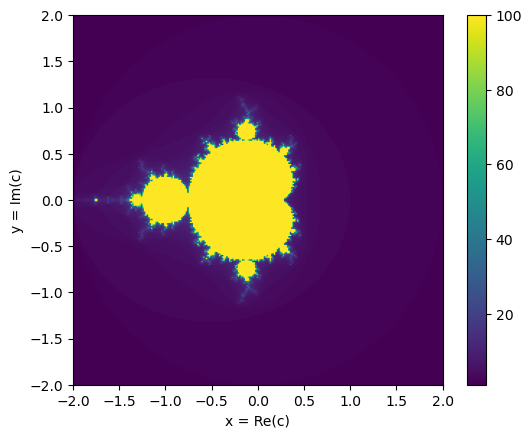

In [17]:
fig = plt.figure()
ax = fig.add_subplot(111)
im = ax.imshow(n.transpose(), origin="lower", extent=[-2, 2, -2, 2]) # I use transpose to have x orizontal axis and y the vertical axis, otherwise axis are inverted
fig.colorbar(im, ax=ax)
ax.set_xlabel("x = Re(c)")
ax.set_ylabel("y = Im(c)")


## Q8: Game of Life visualization

If you've implemented Conway's Game of Life from last lecture, make a visualization of your result using matplotlib

In [18]:
def neighbours(grid):
    # I provide a grid of 0 (dead) and 1 (alive)
    n, m = grid.shape

    # to avoid errors because I am outside the grid, I add zeros around it
    large_box = np.zeros((n+2, m+2), dtype=int)
    large_box[1:-1, 1:-1] = grid # the grid is in the middle of the large box

    # I create a new grid nxm that has for each cell the number of neighbours, I will apply the 4 rules looking this new grid
    total = np.zeros((n, m), dtype=int)
    for x in range(3): # 0 = shift to the left, 2 = shift to the right
        for y in range(3):
            if not (x == 1 and y == 1): # when x = y = 1 means that the grid is not shifting, so I don't consider this combination
                total += large_box[x:x+n, y:y+m]   # I shift the grid nxm in 8 different directions inside the large box, and i sum the 1

    return total


def rules(grid):
    number = neighbours(grid)

    # I apply the rules, I take cells that are alive or born
    # these are true or false matrices
    live = np.logical_and(grid == 1, np.logical_or(number == 2, number == 3))
    reproduction = np.logical_and(grid == 0, number == 3)

    # in the next generation there are 1 in cells which are live or born by reproduction
    next_generation = np.zeros(grid.shape, dtype=int)
    next_generation[np.logical_or(live, reproduction)] = 1

    return next_generation

In [19]:
grid = np.zeros((30, 30), dtype=int)
random.seed(42)
for k in range(100):
    i = random.randint(0, 29)
    j = random.randint(0, 29)
    grid[i, j] = 1

# I save all generations starting from the first
generations = []
generations.append(grid)

num_of_generations = 7

for gen in range(1, num_of_generations + 1):
    grid = rules(grid)
    generations.append(grid)

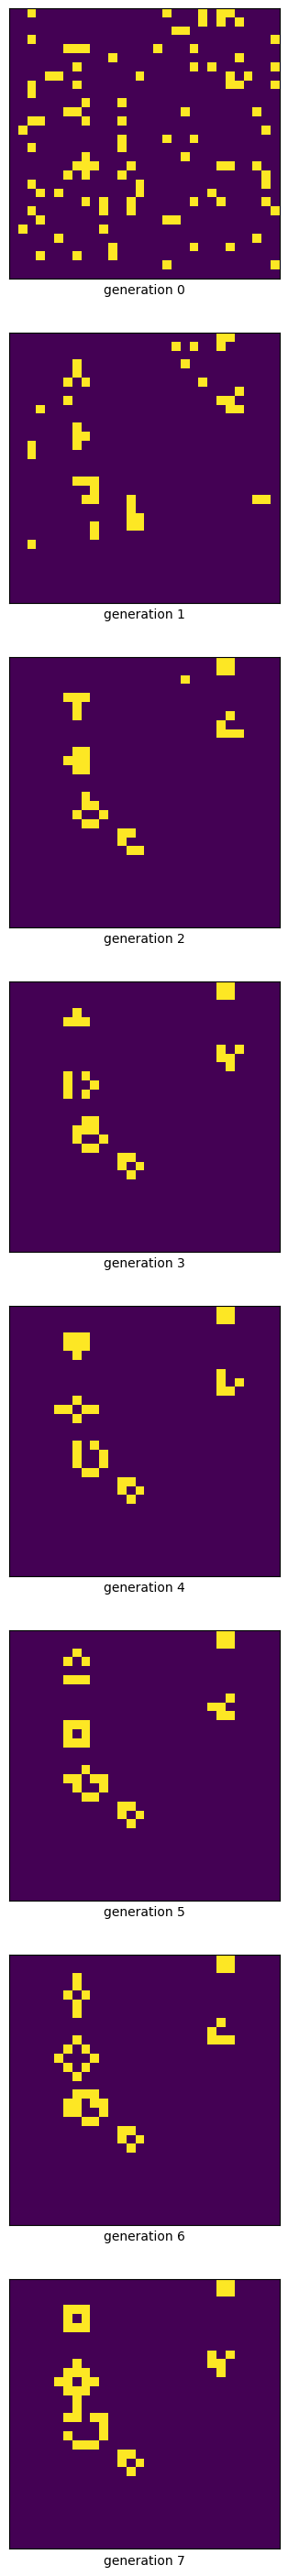

In [20]:
fig = plt.figure()
fig.set_size_inches(5, 5 * num_of_generations+1)

for k in range(num_of_generations+1):
    ax = fig.add_subplot(num_of_generations+1, 1, k+1)
    ax.imshow(generations[k])
    
    ax.set_xlabel("generation {}".format(k))

    ax.set_xticks([])
    ax.set_yticks([])